# Tutorial 3. A vehicle suspension: ride over a bump, and a sky-hook damper

![A vehicle suspension](../tutorials/images/t03_hero.png)

**Scope:** mechanical engineering. **Components:** `Mass`, `Spring`, `Damper`,
`ForceSource`, `VelocitySource`, `Fixed`.

## The asset

A quarter-car model: one corner of a vehicle, with the sprung mass (a quarter of
the body), the suspension spring and damper, the unsprung mass (wheel, hub,
brake) and the tyre as a stiff spring. The road moves the tyre contact. Two
questions from ride engineering:

- **Comfort.** How large is the body acceleration over a 5 cm bump at 36 km/h,
  and how fast does it settle?
- **Sky-hook.** An idealised active suspension damps the body against the
  inertial frame rather than against the wheel. How much does it help?

![Mechanical schematic](../tutorials/images/t03_pd.png)

Velocity is the across variable, force the through variable. The road is a
velocity source at the tyre contact; a force source on the body represents a
payload or braking load; the frame for the sky-hook damper is a `Fixed` port.

## Step 1. The passive suspension

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns

import otwin
from otwin.components.mechanical import (
    Damper,
    Fixed,
    ForceSource,
    Mass,
    Spring,
    VelocitySource,
)

sns.set_theme(style="whitegrid", palette=["#201E1D", "#EC3013", "#4D86A6", "#8A8886"])

M_S, M_U, K_S, C_S, K_T = 300.0, 40.0, 20e3, 1.5e3, 180e3  # kg, kg, N/m, N s/m, N/m


def quarter_car(c_sky=0.0, c_s=C_S):
    body = Mass(M_S, name="body")
    wheel = Mass(M_U, name="wheel")
    spring = Spring(K_S, name="spring")
    damper = Damper(c_s, name="damper")
    tyre = Spring(K_T, name="tyre")
    road = VelocitySource(None, name="road")  # m/s, an input: the road's vertical speed
    payload = ForceSource(None, name="payload")  # N, an input: + pushes the body up
    car = otwin.System(body, wheel, spring, damper, tyre, road, payload)
    car.connect(body.flange, spring.a, damper.a, payload.flange)
    car.connect(spring.b, damper.b, wheel.flange, tyre.a)
    car.connect(tyre.b, road.flange)
    if c_sky > 0:
        sky = Damper(c_sky, name="skyhook")
        frame = Fixed(name="frame")
        car.add(sky, frame)
        car.connect(body.flange, sky.a)
        car.connect(sky.b, frame.port)
    return otwin.compile(car)


passive = quarter_car()
print(passive.summary())
w_body = np.sqrt(K_S / M_S)
w_wheel = np.sqrt((K_S + K_T) / M_U)
print(
    f"body mode {w_body / 2 / np.pi:.2f} Hz, wheel hop {w_wheel / 2 / np.pi:.1f} Hz, "
    f"damping ratio of the body mode {C_S / (2 * np.sqrt(K_S * M_S)):.2f}"
)

System: system

Components:
  body                         mass [mechanical]
  wheel                        mass [mechanical]
  spring                       spring [mechanical]
  damper                       damper [mechanical]
  tyre                         spring [mechanical]
  road                         velocity_source [mechanical]
  payload                      force [mechanical]

States:
  body.momentum                momentum [kg m/s]  x0 = 0
  wheel.momentum               momentum [kg m/s]  x0 = 0
  spring.extension             extension [m]  x0 = 0
  tyre.extension               extension [m]  x0 = 0

Inputs:
  road                         velocity [m/s]
  payload                      force [N]

Parameters:
  body.mass                    300          kg
  wheel.mass                   40           kg
  spring.stiffness             20000        N/m
  damper.damping               1500         N s/m
  tyre.stiffness               180000       N/m

Outputs: 30 named quantities (mo

Four states: the momentum of each mass and the extension of each spring. The two
natural frequencies, about 1.3 Hz for the body and 11 Hz for the wheel hop, are
the textbook values for a passenger car, and the body mode is damped at about a
third of critical, which is where ride engineers put it.

## Step 2. Drive over a bump

A cosine bump 5 cm high and 3 m long, crossed at 36 km/h (10 m/s), lasts 0.3 s.
The road input is the vertical *velocity* of the contact point, the derivative of
the profile.

In [ ]:
V_CAR, H_BUMP, L_BUMP = 10.0, 0.05, 3.0
dt = 1e-3
t = np.arange(0.0, 3.0, dt)


def road_velocity(time):
    tau = time - 0.2
    if 0 <= tau <= L_BUMP / V_CAR:
        return (
            H_BUMP
            / 2
            * (2 * np.pi * V_CAR / L_BUMP)
            * np.sin(2 * np.pi * V_CAR * tau / L_BUMP)
        )
    return 0.0


def ride(model):
    out = model.simulate(
        t=t, inputs={"road": road_velocity, "payload": 0.0}, solver="rk4"
    )
    body_v = out["body.velocity"]
    return out, body_v, np.gradient(body_v, dt)


run, v_body, a_body = ride(passive)
travel = run["spring.extension"] * 1e3
print(
    f"peak body acceleration {np.max(np.abs(a_body)):.2f} m/s2 ({np.max(np.abs(a_body)) / 9.81:.2f} g)"
)
print(f"suspension travel: {travel.min():.1f} to {travel.max():.1f} mm")
settle = t[np.flatnonzero(np.abs(a_body) > 0.05)[-1]]
print(
    f"body acceleration below 0.05 m/s2 after t = {settle:.2f} s ({settle - 0.2:.2f} s after the bump)"
)

peak body acceleration 4.60 m/s2 (0.47 g)
suspension travel: -32.7 to 41.1 mm
body acceleration below 0.05 m/s2 after t = 2.19 s (1.99 s after the bump)


The body sees a fraction of a g; the wheel takes most of the bump. The
suspension compresses and then rebounds over the body's natural period, and the
motion dies out in a couple of cycles, as the damping ratio predicts.

## Step 3. Add a sky-hook damper

A sky-hook damper is a damper between the body and an imaginary fixed frame
above the car. It cannot be built mechanically, but an active suspension can
apply the same force, and it is the reference every active design is measured
against. In Otwin it is a `Damper` to a `Fixed` port. A sky-hook design moves
damping from the passive damper to the sky-hook, so the passive damper is
reduced in the variants below.

In [ ]:
rows = []
traces = []
for label, c_sky, c_s in (
    ("passive", 0.0, C_S),
    ("sky-hook 2 kN s/m, passive 0.5", 2.0e3, 500.0),
    ("sky-hook 3 kN s/m, passive 0.5", 3.0e3, 500.0),
):
    model = quarter_car(c_sky, c_s)
    out, v, a = ride(model)
    rows.append(
        {
            "suspension": label,
            "peak body accel (m/s2)": np.max(np.abs(a)),
            "rms body accel (m/s2)": np.sqrt(np.mean(a**2)),
            "peak travel (mm)": np.max(np.abs(out["spring.extension"])) * 1e3,
            "peak tyre force (kN)": np.max(np.abs(out["tyre.force"])) / 1e3,
        }
    )
    traces.append(
        pd.DataFrame({"time (s)": t, "body acceleration (m/s2)": a, "suspension": label})
    )
print(pd.DataFrame(rows).round(3).to_string(index=False))

                    suspension  peak body accel (m/s2)  rms body accel (m/s2)  peak travel (mm)  peak tyre force (kN)
                       passive                   4.596                  1.044            41.106                 1.337
sky-hook 2 kN s/m, passive 0.5                   2.433                  0.561            37.869                 0.913
sky-hook 3 kN s/m, passive 0.5                   2.112                  0.471            38.496                 0.913


With most of the damping moved to the sky-hook, the body acceleration roughly
halves, peak and rms, because the bump no longer reaches the body through a
stiff damper. Suspension travel and tyre force fall a little as well: the soft
passive damper transmits less of the wheel's motion. That is why the sky-hook is
the reference design. The price is an actuator and a measurement of body
velocity, and a real semi-active damper can only approximate it.

## Step 4. Plot the ride

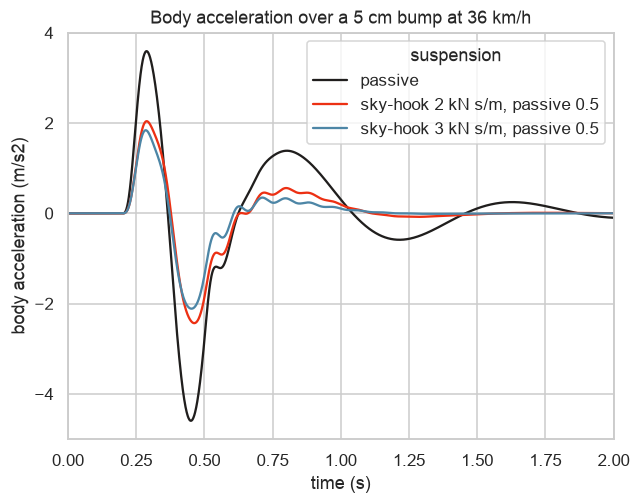

In [ ]:
ax = sns.lineplot(
    data=pd.concat(traces), x="time (s)", y="body acceleration (m/s2)", hue="suspension"
)
ax.set_xlim(0, 2.0)
ax.set_title("Body acceleration over a 5 cm bump at 36 km/h")

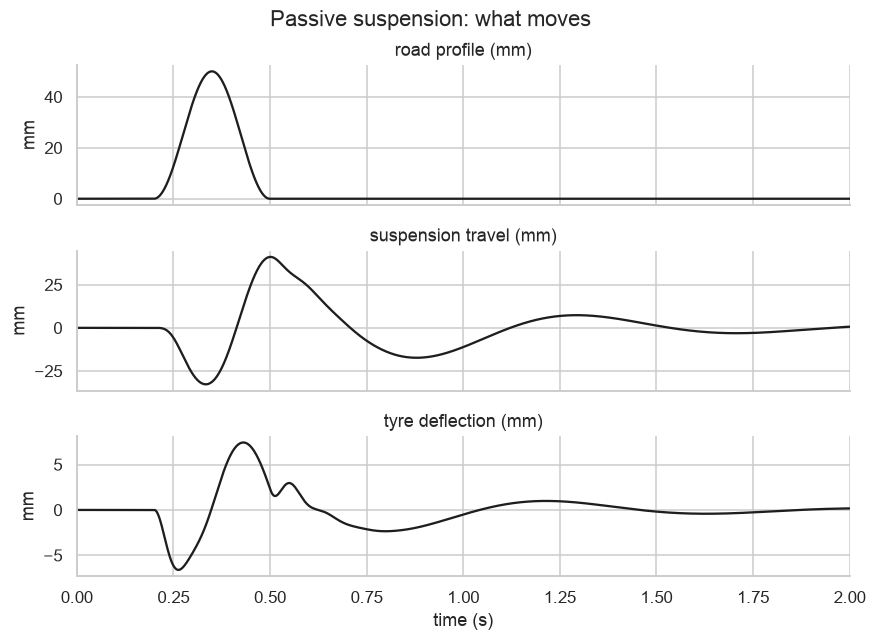

In [ ]:
profile = np.cumsum([road_velocity(x) for x in t]) * dt * 1e3
frame = pd.DataFrame(
    {
        "time (s)": t,
        "road profile (mm)": profile,
        "suspension travel (mm)": travel,
        "tyre deflection (mm)": run["tyre.extension"] * 1e3,
    }
)
long = frame.melt("time (s)", var_name="signal", value_name="mm")
g = sns.relplot(
    data=long,
    x="time (s)",
    y="mm",
    row="signal",
    kind="line",
    height=1.9,
    aspect=4.2,
    facet_kws={"sharey": False},
    color="#201E1D",
)
g.set_titles("{row_name}")
g.set(xlim=(0, 2.0))
g.figure.suptitle("Passive suspension: what moves", y=1.02)

The tyre deflects by nearly the bump height in the 0.1 s it takes to cross, then
rings at the wheel-hop frequency; the suspension travel is the slower, larger
body motion. Both are the quantities a test rig measures, and both are outputs
of the compiled model by name.

## Step 5. A payload

The same model answers a static question. Put 150 kg on this corner as a force
and read the suspension sag.

In [ ]:
static = passive.simulate(
    t=np.arange(0, 6, 1e-3),
    inputs={"road": 0.0, "payload": -150 * 9.81},
    solver="midpoint",
)
print(
    f"sag under 150 kg: {-static['spring.extension'][-1] * 1e3:.1f} mm of compression "
    f"(hand check F/k = {150 * 9.81 / K_S * 1e3:.1f} mm)"
)

sag under 150 kg: 73.6 mm of compression (hand check F/k = 73.6 mm)


The spring compresses by F/k: the model agrees with the hand calculation to the
last digit, which is the check to run on every model before trusting it with a
harder question.

## What to take from this

- Masses, springs and dampers connect at nodes where velocities are shared and
  forces balance; the compiler writes Newton's laws.
- A `VelocitySource` drives a point; a `ForceSource` pushes on one; `Fixed` is the
  frame.
- Every force and displacement in the model is an output by name, so a test-rig
  quantity is one lookup.

Next: [Tutorial 4](04_wind_turbine_drivetrain.md) does the same with rotation.